# Etapa F — Hamilton–Jacobi–Bellman

In [1]:
using Pkg
project = dirname(Base.active_project())
include(joinpath(project, "src", "FitzHughNagumoControl.jl"))
using .FitzHughNagumoControl
println("Proyecto activo: ",project)


Proyecto activo: k:\Repositorios\Proyecto-COPTI


## 1. Sincronización, HJB estacionaria reducida
La reducción es válida solamente para N=2 con `v*=0`. En esta subvariedad `E=dᵥ²+d𝓌²`, y las fases geométricas están opuestas (`r²=0`) salvo en el centro. Su finalidad es ilustrar HJB sin alterar el modelo.


Puntos resueltos: 59 / 2091
W(d0) ≈ Inf


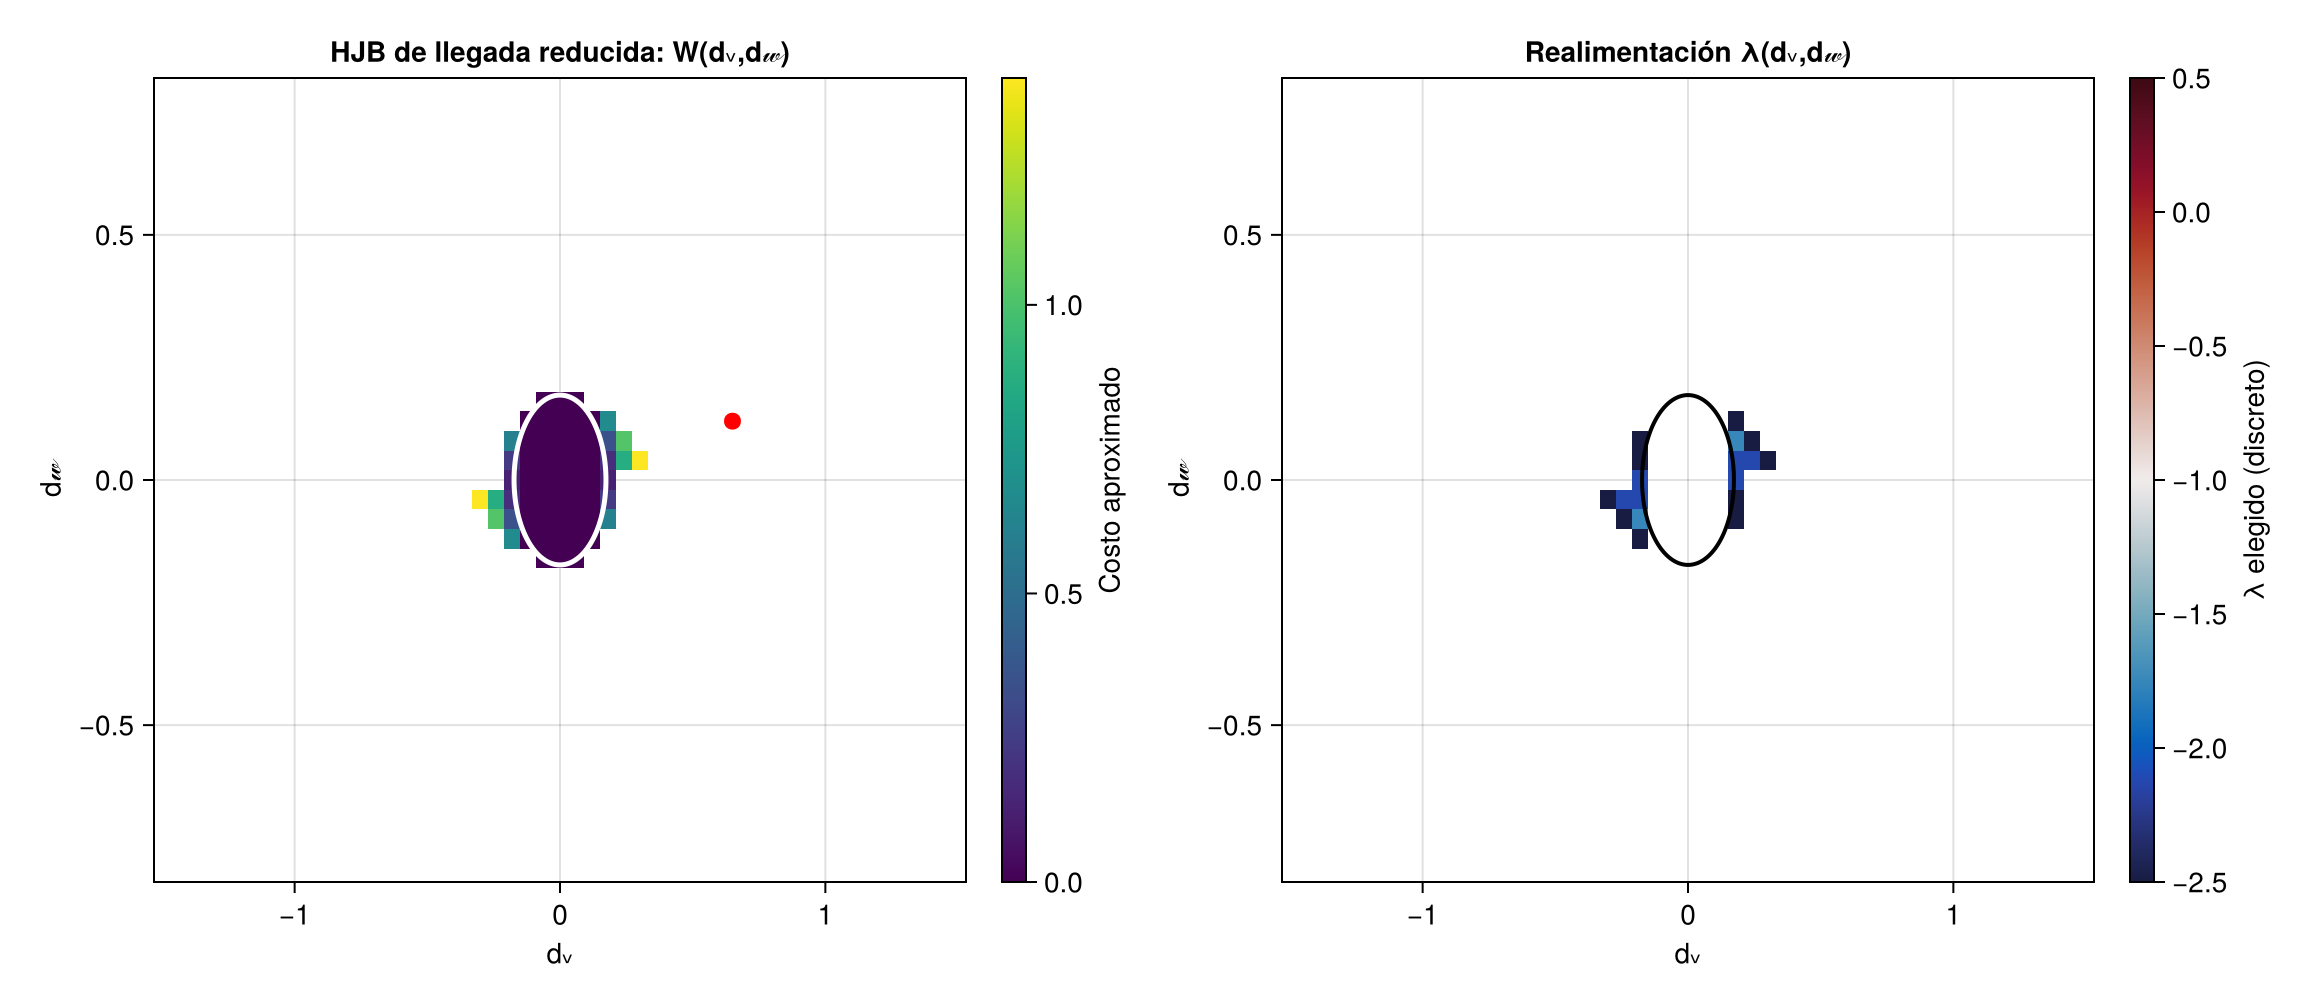

CairoMakie.Screen{IMAGE}


In [2]:
p = FHNParameters(a=0.7,b=0.5,tau=12.5,I=1.4)
d0 = [0.65,0.12]
sp = SyncOCPSpec(p,2,reduced_sync_state(d0,p); delta=0.03)
hs = solve_reduced_sync_hjb(sp)
println("Puntos resueltos: ",count(isfinite,hs.W)," / ",length(hs.W))
println("W(d0) ≈ ",reduced_sync_value(hs,d0))
display(plot_hjb_sync(hs;d0=d0))


In [3]:
syn_hjb = rollout_reduced_sync(hs,d0;mode=:hjb,dt=0.05)
syn_const = rollout_reduced_sync(hs,d0;mode=:constant,lambda_constant=-1.5,dt=0.05)
println("HJB: ",syn_hjb.status," T=",syn_hjb.t[end]," J=",syn_hjb.J[end]," uncovered=",syn_hjb.uncovered_steps)
println("Constante: ",syn_const.status," T=",syn_const.t[end]," J=",syn_const.J[end])


HJB: reached T=0.9685637659171576 J=3.4107156532019225 uncovered=14
Constante: reached T=1.7779382421656695 J=3.780948738074111


## 2. Desincronización, HJB temporal N=2 en 4D
Como `u₁+u₂=0`, toda corriente admisible es `(q,−q)`. Aquí la ecuación de Bellman se discretiza en una grilla pequeña, con un horizonte más corto que el caso N=4 de la Etapa E.


HJB discreta: J=11.599999999999998 r²(T)=0.9999999999999999 cubierta=false
u=0: J=11.599999999999998 r²(T)=0.9999999999999999


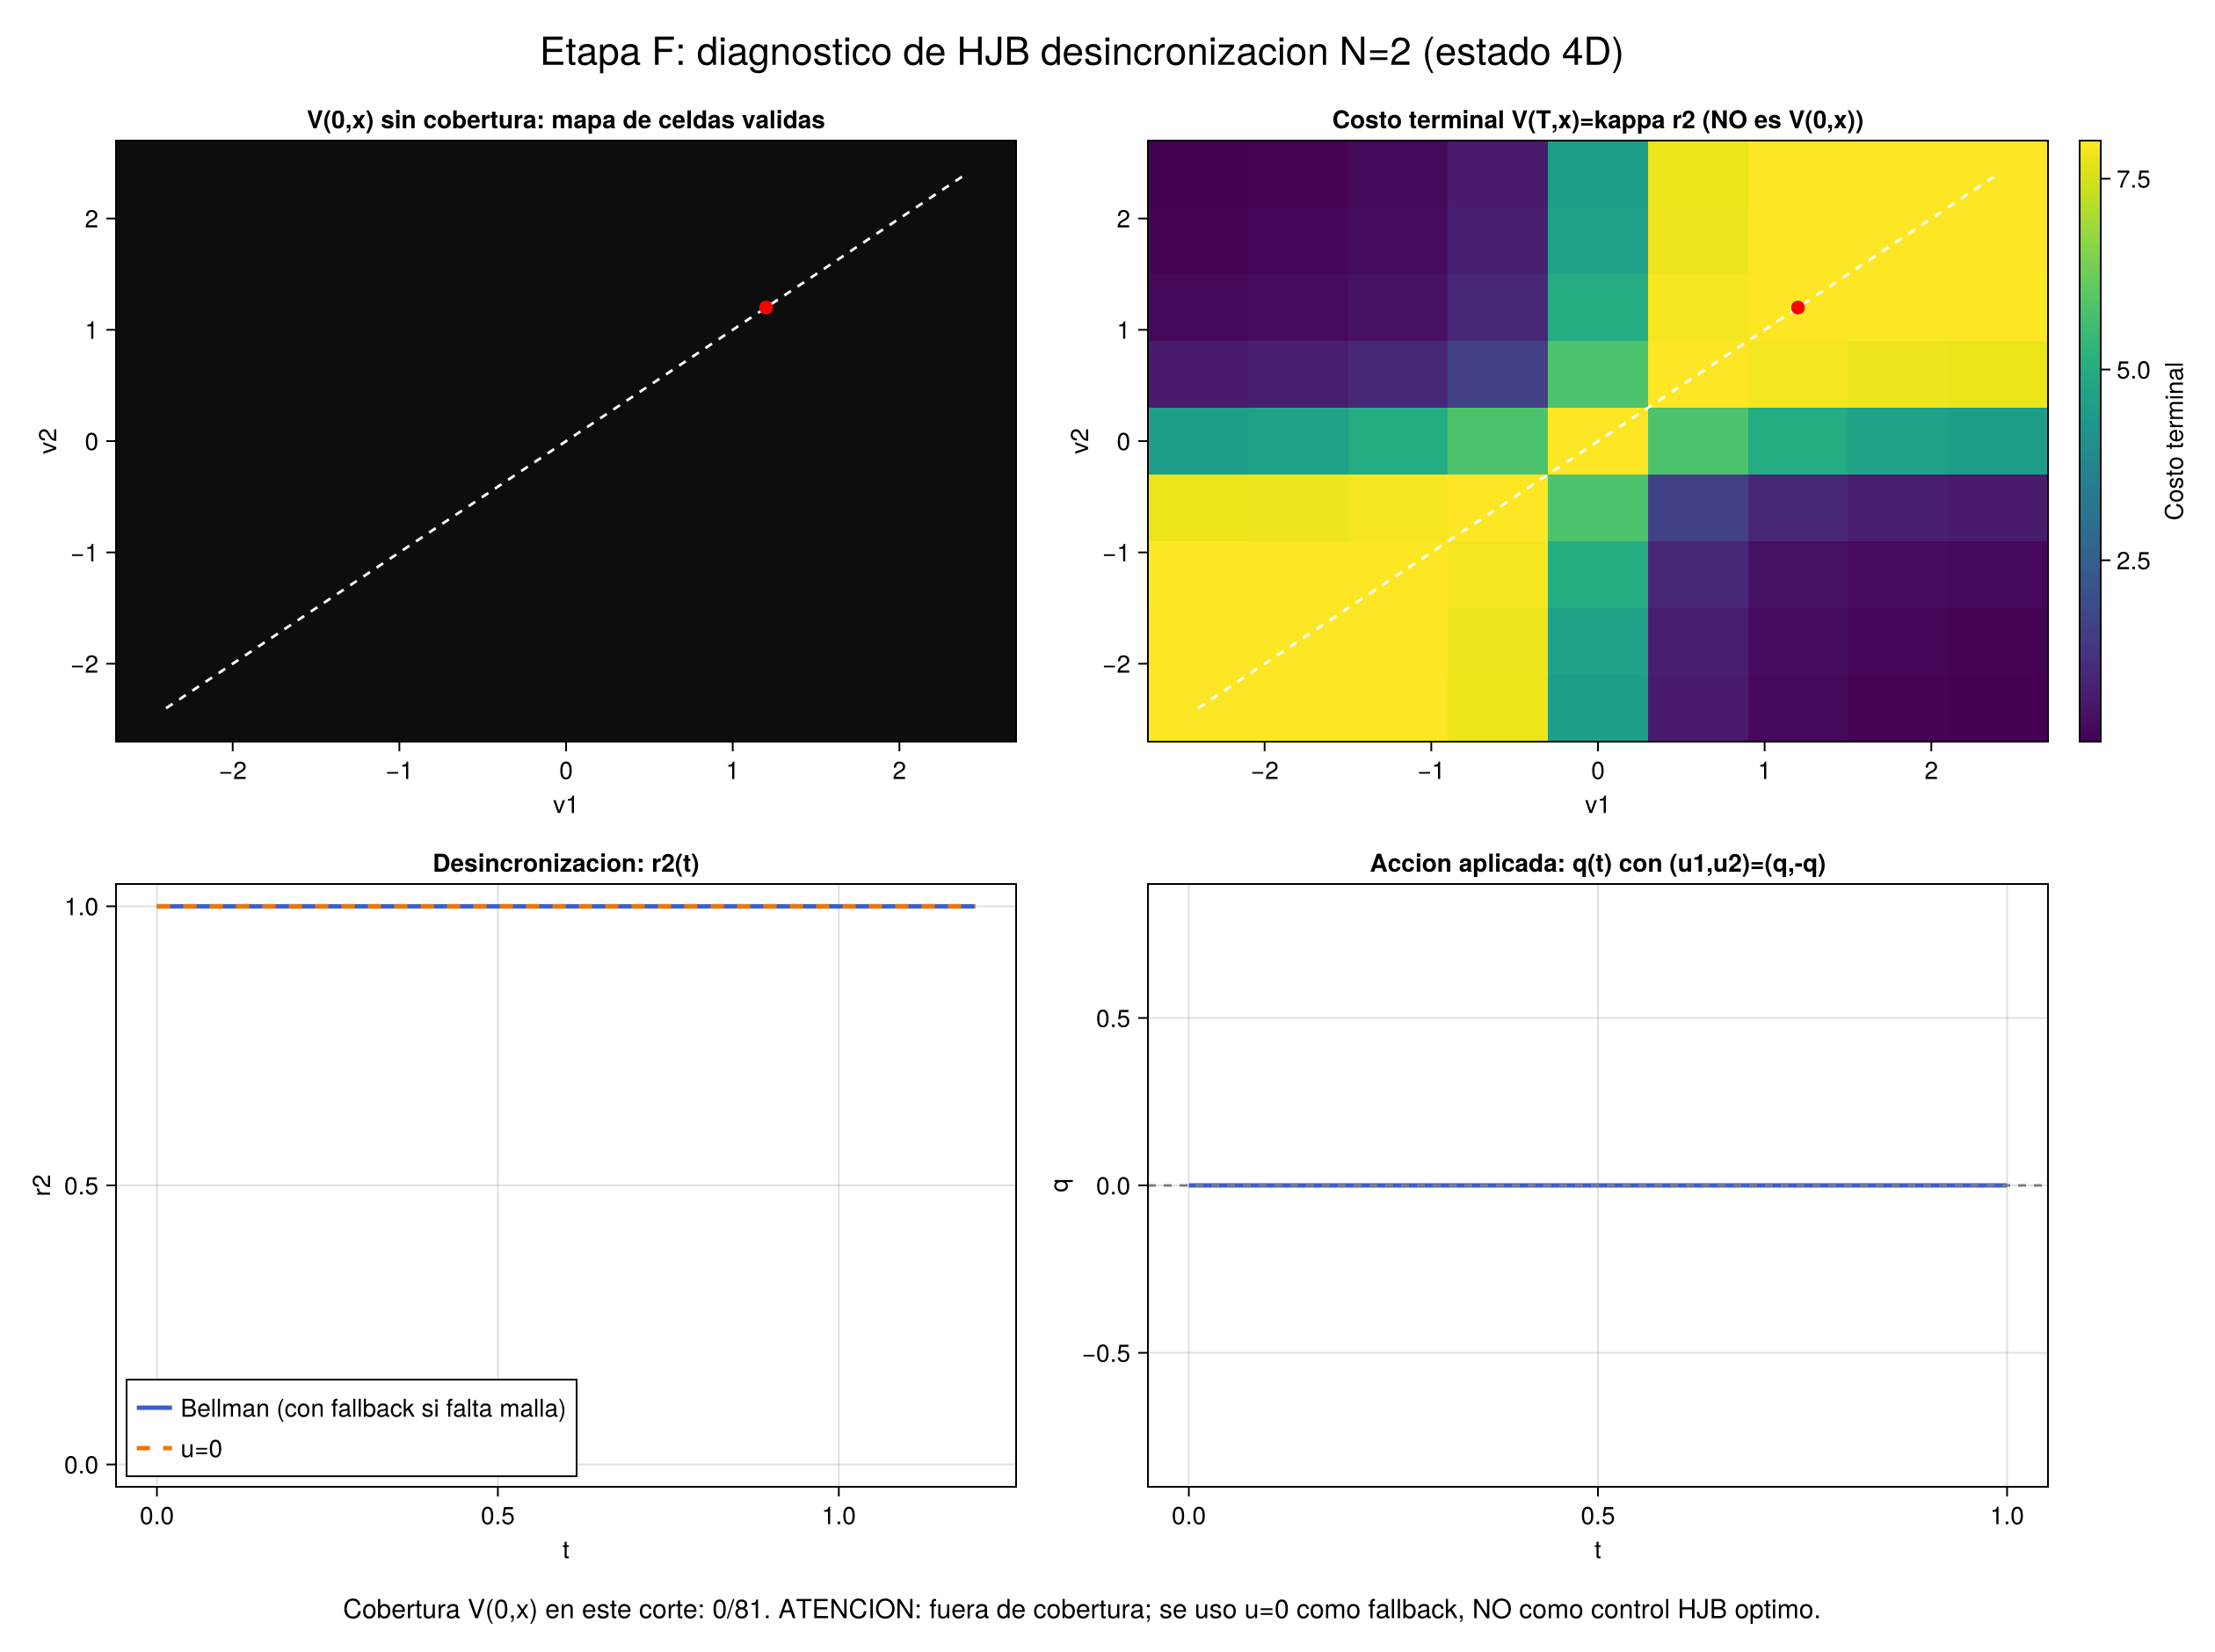

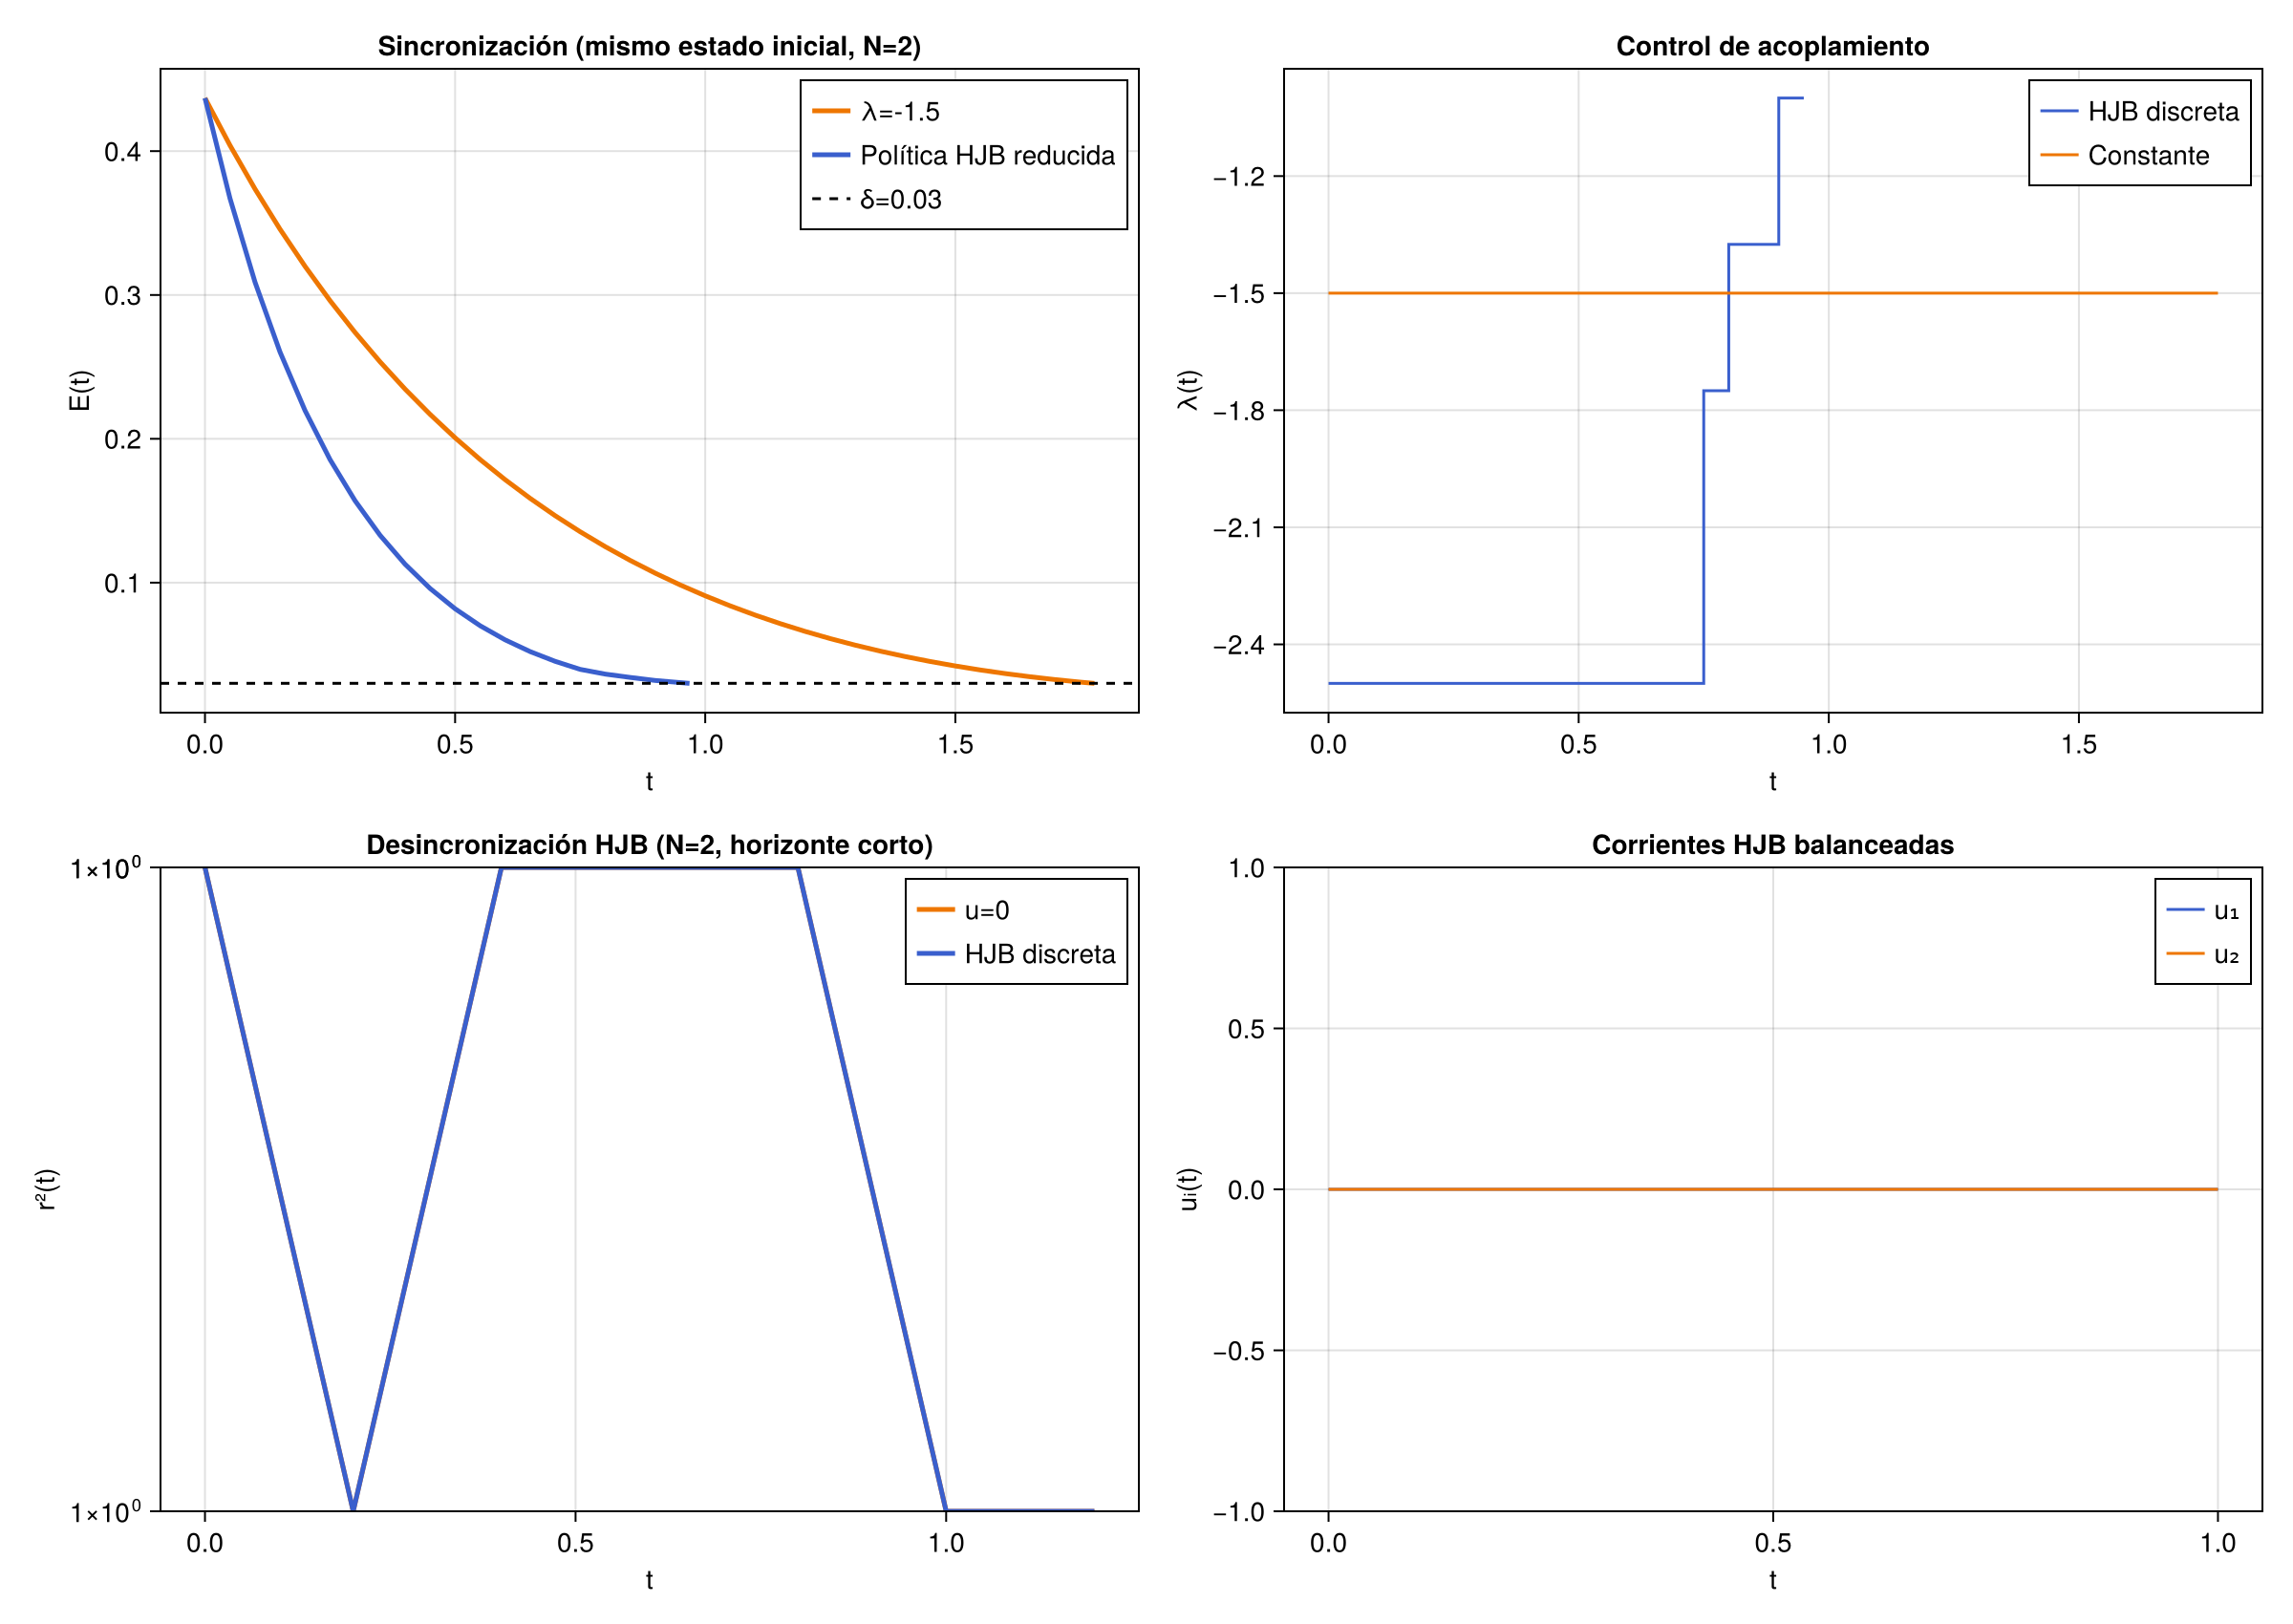

CairoMakie.Screen{IMAGE}


In [4]:
ds = DesyncOCPSpec(p,2,synchronized_state(2,[1.2,1.1]);T=1.2,lambda0=-0.15,Umax=0.8,alpha_d=3.0,gamma_d=0.05,kappa=8.0)
hd = solve_small_desync_hjb(ds;steps=6)
des_hjb = rollout_small_desync(hd;mode=:hjb)
des_zero = rollout_small_desync(hd;mode=:zero)
println("HJB discreta: J=",des_hjb.final_J," r²(T)=",des_hjb.terminal_r2," cubierta=",des_hjb.covered)
println("u=0: J=",des_zero.final_J," r²(T)=",des_zero.terminal_r2)
display(plot_hjb_desync(hd))
display(plot_hjb_comparison(syn_hjb,syn_const,des_hjb,des_zero))
